# Takata 2025 2D Models with Axionlike Production

Neutrino data for 1-D core-collapse supernova models in the presence of axion-like particles.

The reference article is [Progenitor dependence of neutrino-driven supernova explosions with the aid of heavy axionlike particles](https://doi.org/10.1103/PhysRevD.111.103028) by T. Takata et al., Phys. Rev. D 111:103028, 2025.

The following models are supported:

## ALP parameters and progenitor masses simulated

| Progenitor mass [Msun] | Axion mass [MeV] | Axion-photon coupling [1e-10/GeV] |
| ---------------------- | ---------------- | --------------------------------- |
| 11.2 | 0, 40, 100, 150, 200, 300, 400, 600, 800 | 0, 2, 4, 6, 8, 10 |
| 20 | 0, 40, 100, 150, 200, 300, 400, 600, 800 | 0, 2, 4, 6, 8, 10 |
| 25 | 0, 40, 100, 150, 200, 300, 400, 600, 800 | 0, 2, 4, 6, 8, 10 |

In [1]:
from snewpy.neutrino import Flavor
from snewpy.models.ccsn import Takata_2025

from astropy import units as u

from scipy.interpolate import PchipInterpolator

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
mpl.rc('font', size=16)

## Initialize the 2D models

Use the `param` property of the model class to see the available parameters. Models are initialized using the `axion_mass` and `axion_coupling` parameters.

In [3]:
Takata_2025.param

{'progenitor_mass': <Quantity [11.2, 20. , 25. ] solMass>,
 'axion_mass': <Quantity [  0.,  40., 100., 150., 200., 300., 400., 600., 800.] MeV>,
 'axion_coupling': <Quantity [ 0.,  4.,  6.,  8., 10.] 1e-10 / GeV>}

The model with `axion_mass=0` and `axion_coupling=0` is a standard simulation with no ALP production.

We'll use the model with a 25 M$_\odot$ progenitor.

In [7]:
pmass = 20*u.Msun
model_std = Takata_2025(axion_mass=0, axion_coupling=0, progenitor_mass=pmass)
model_std.metadata

{'Progenitor mass': <Quantity 20. solMass>,
 'Axion mass': 0,
 'Axion coupling': <Quantity 0. 1e-10 / GeV>}

In [8]:
# Initialize a handful of axion models.
models = {}
for (am, ac) in ((40*u.MeV, 4e-10/u.GeV), (100*u.MeV, 6e-10/u.GeV), (200*u.MeV, 6e-10/u.GeV), (300*u.MeV, 8e-10/u.GeV), (400*u.MeV, 10e-10/u.GeV), (600*u.MeV, 6e-10/u.GeV)):
    models[(am,ac)] = Takata_2025(axion_mass=am, axion_coupling=ac, progenitor_mass=pmass)

models

{(<Quantity 40. MeV>,
  <Quantity 4.e-10 1 / GeV>): Takata_2025 Model: 20_040_04.dat
 Progenitor mass  : 20.0 solMass
 Axion mass       : 40.0 MeV
 Axion coupling   : 4.0 1e-10 / GeV,
 (<Quantity 100. MeV>,
  <Quantity 6.e-10 1 / GeV>): Takata_2025 Model: 20_100_06.dat
 Progenitor mass  : 20.0 solMass
 Axion mass       : 100.0 MeV
 Axion coupling   : 6.0 1e-10 / GeV,
 (<Quantity 200. MeV>,
  <Quantity 6.e-10 1 / GeV>): Takata_2025 Model: 20_200_06.dat
 Progenitor mass  : 20.0 solMass
 Axion mass       : 200.0 MeV
 Axion coupling   : 6.0 1e-10 / GeV,
 (<Quantity 300. MeV>,
  <Quantity 8.e-10 1 / GeV>): Takata_2025 Model: 20_300_08.dat
 Progenitor mass  : 20.0 solMass
 Axion mass       : 300.0 MeV
 Axion coupling   : 8.0 1e-10 / GeV,
 (<Quantity 400. MeV>,
  <Quantity 1.e-09 1 / GeV>): Takata_2025 Model: 20_400_10.dat
 Progenitor mass  : 20.0 solMass
 Axion mass       : 400.0 MeV
 Axion coupling   : 10.0 1e-10 / GeV,
 (<Quantity 600. MeV>,
  <Quantity 6.e-10 1 / GeV>): Takata_2025 Model:

## Plot Model Luminosities

Compare axion model luminosity to the standard 2D simulation.

Higher mass models with stronger coupling constants should produce a decrease in neutrino luminosity at all flavors relative to the reference simulation.

In [9]:
model_std.metadata["Progenitor mass"].to_value("Msun")

np.float64(20.0)

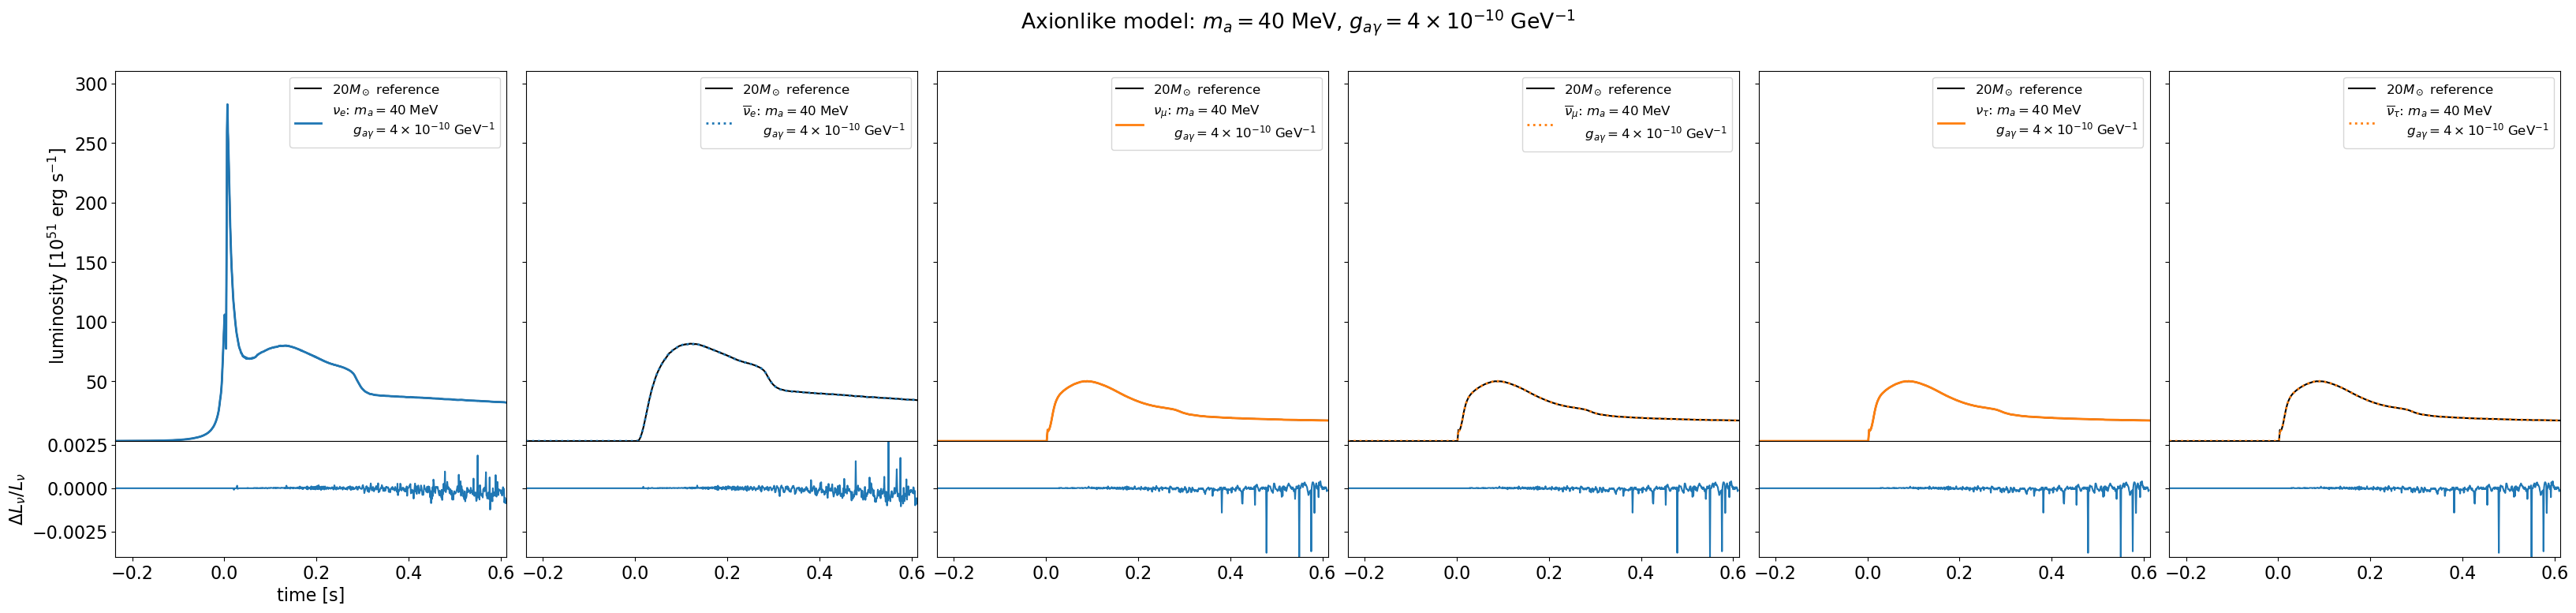

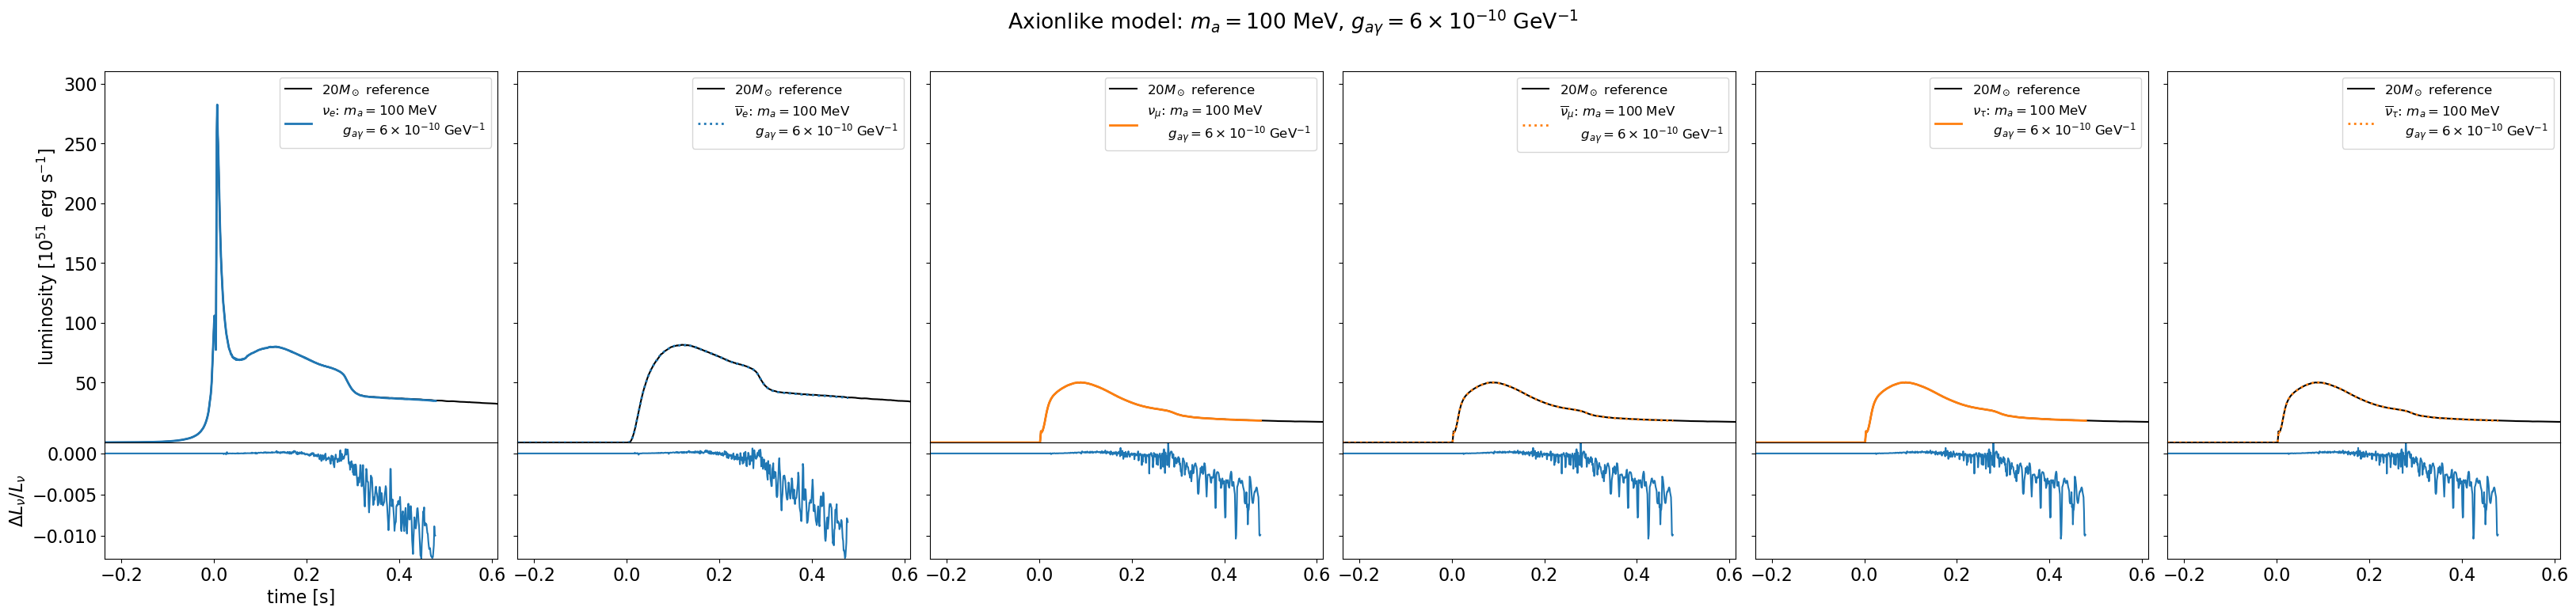

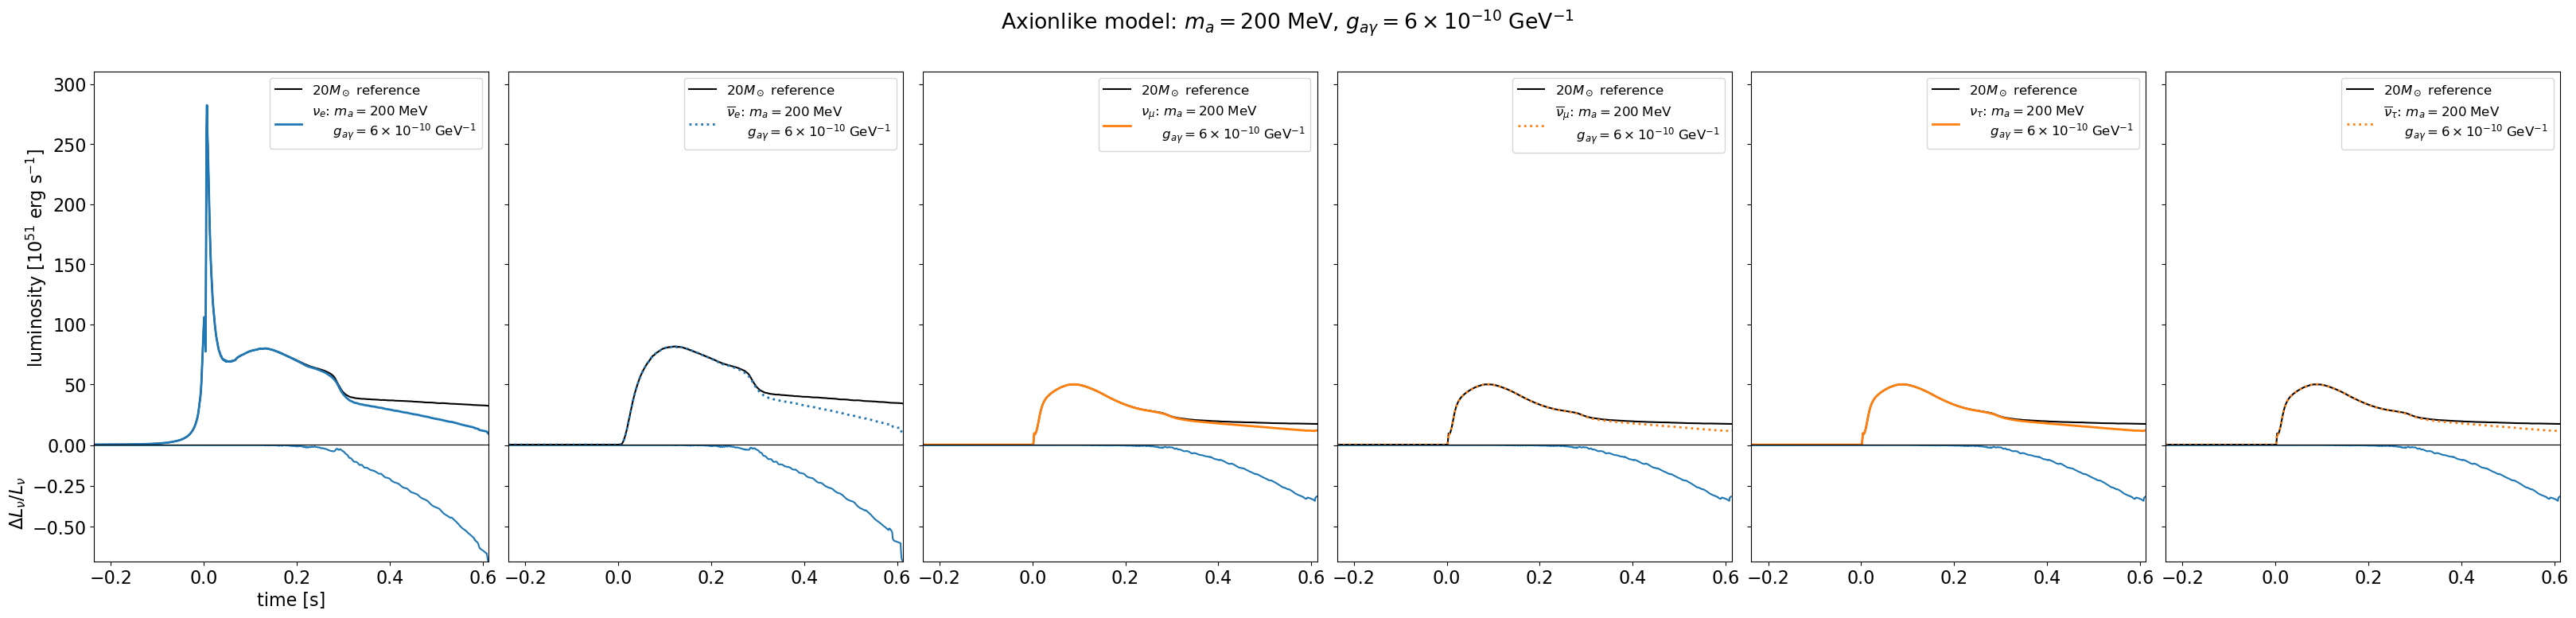

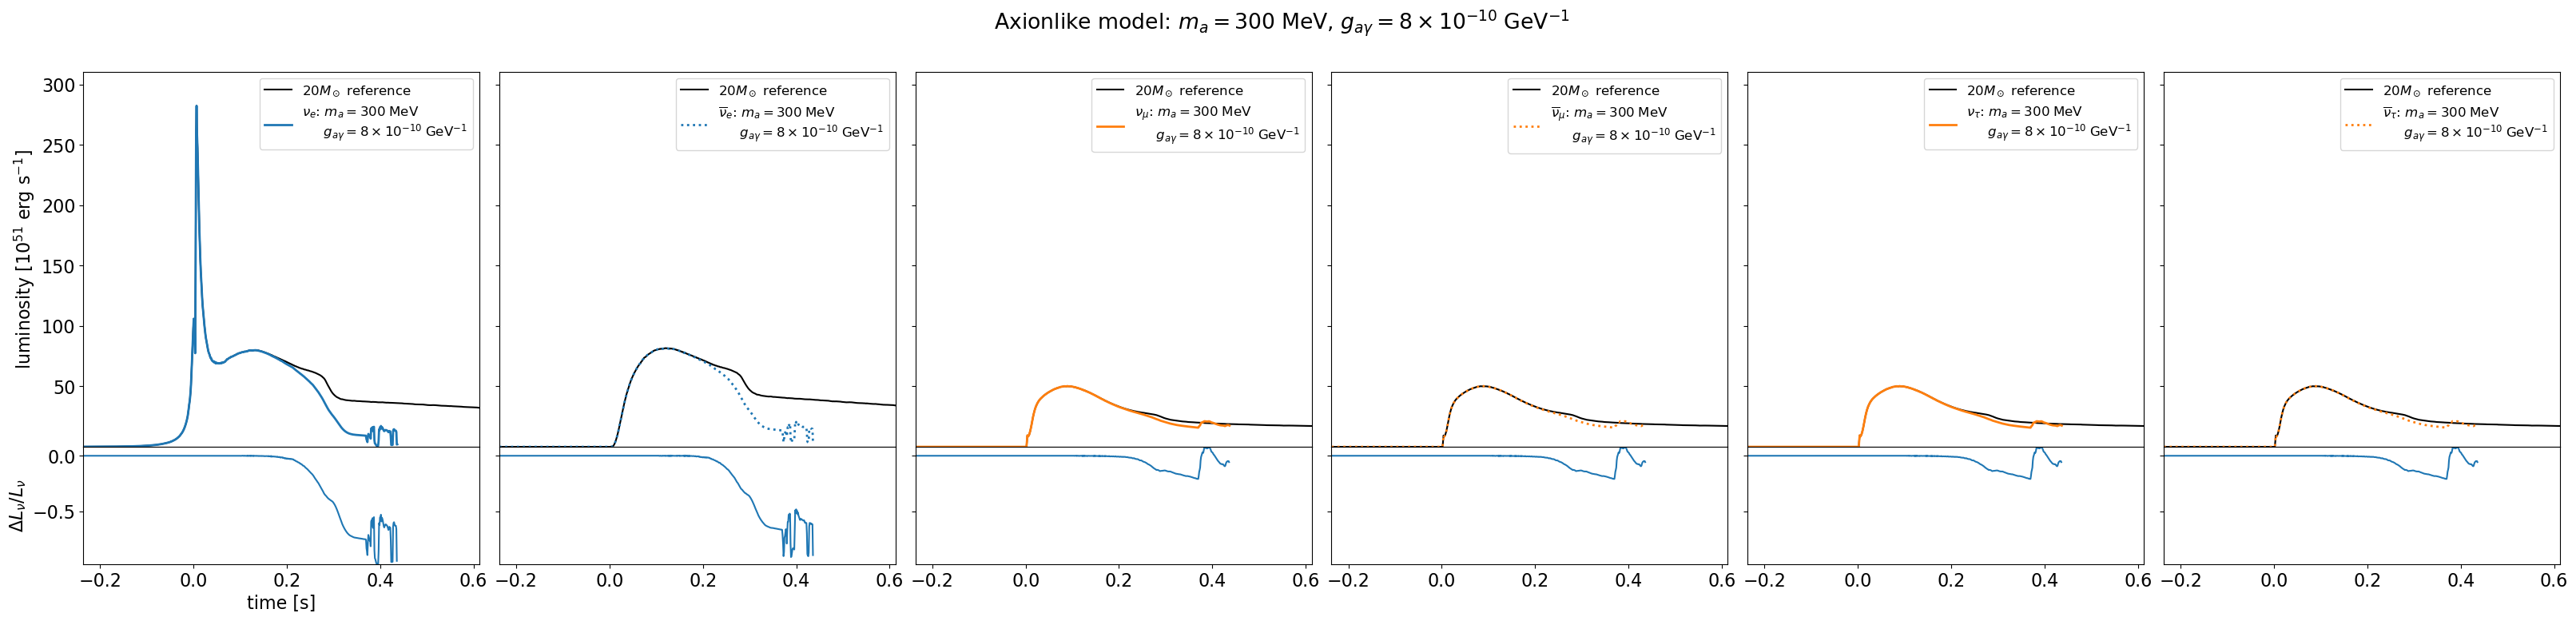

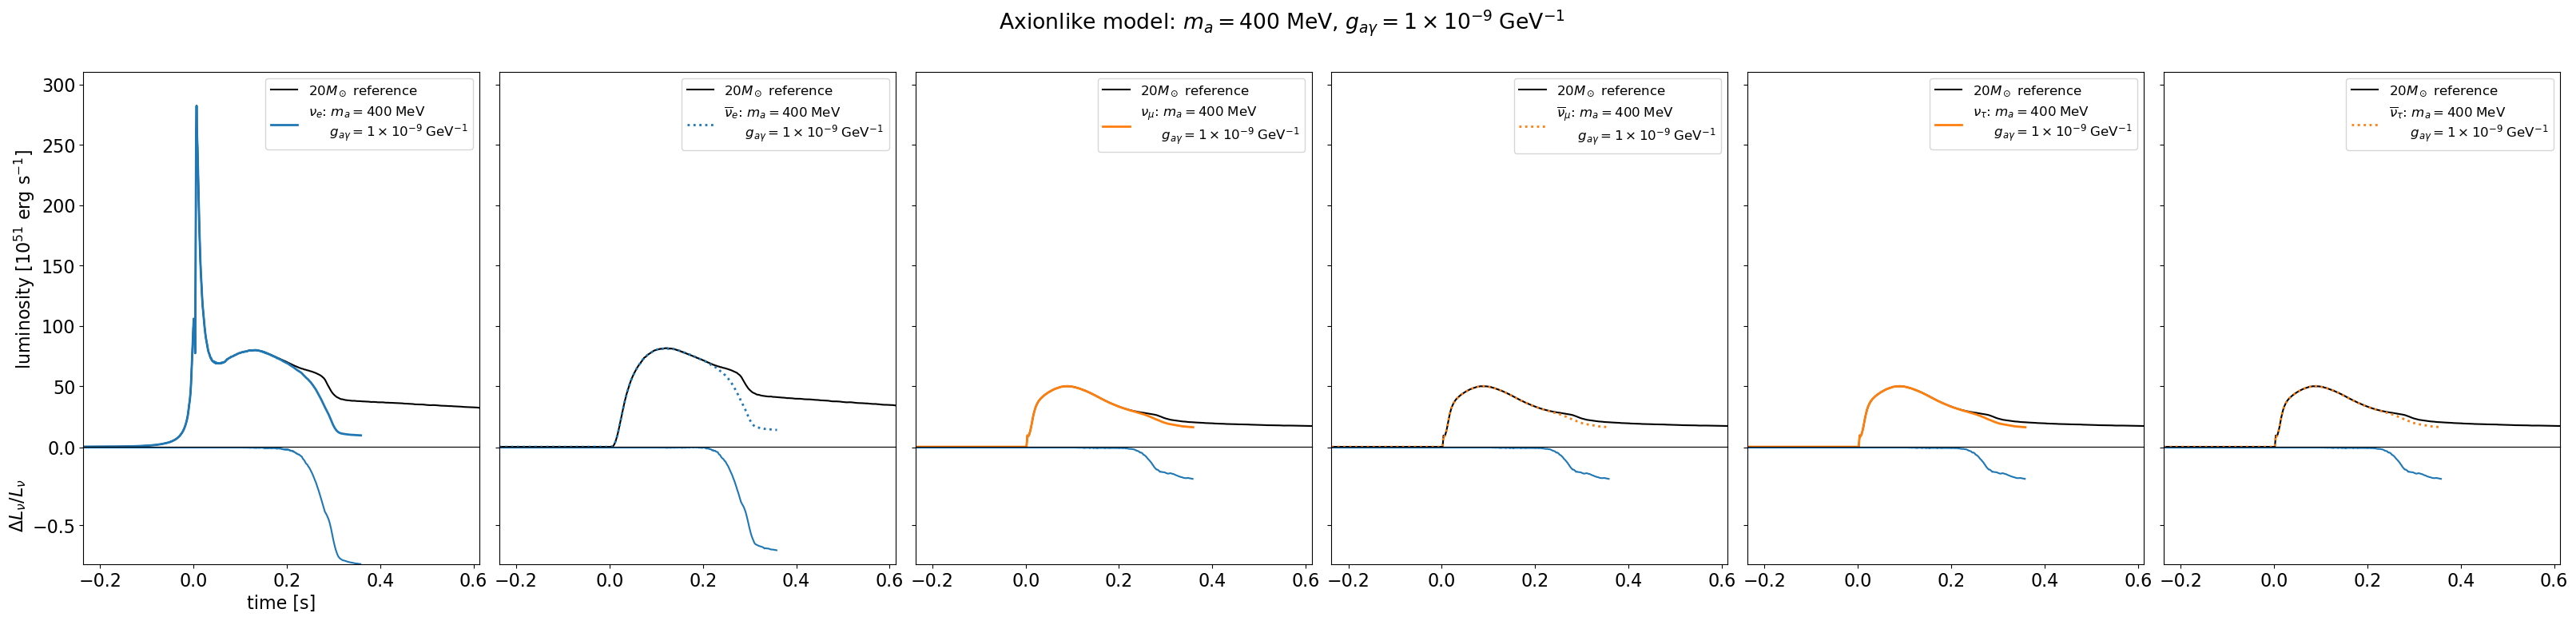

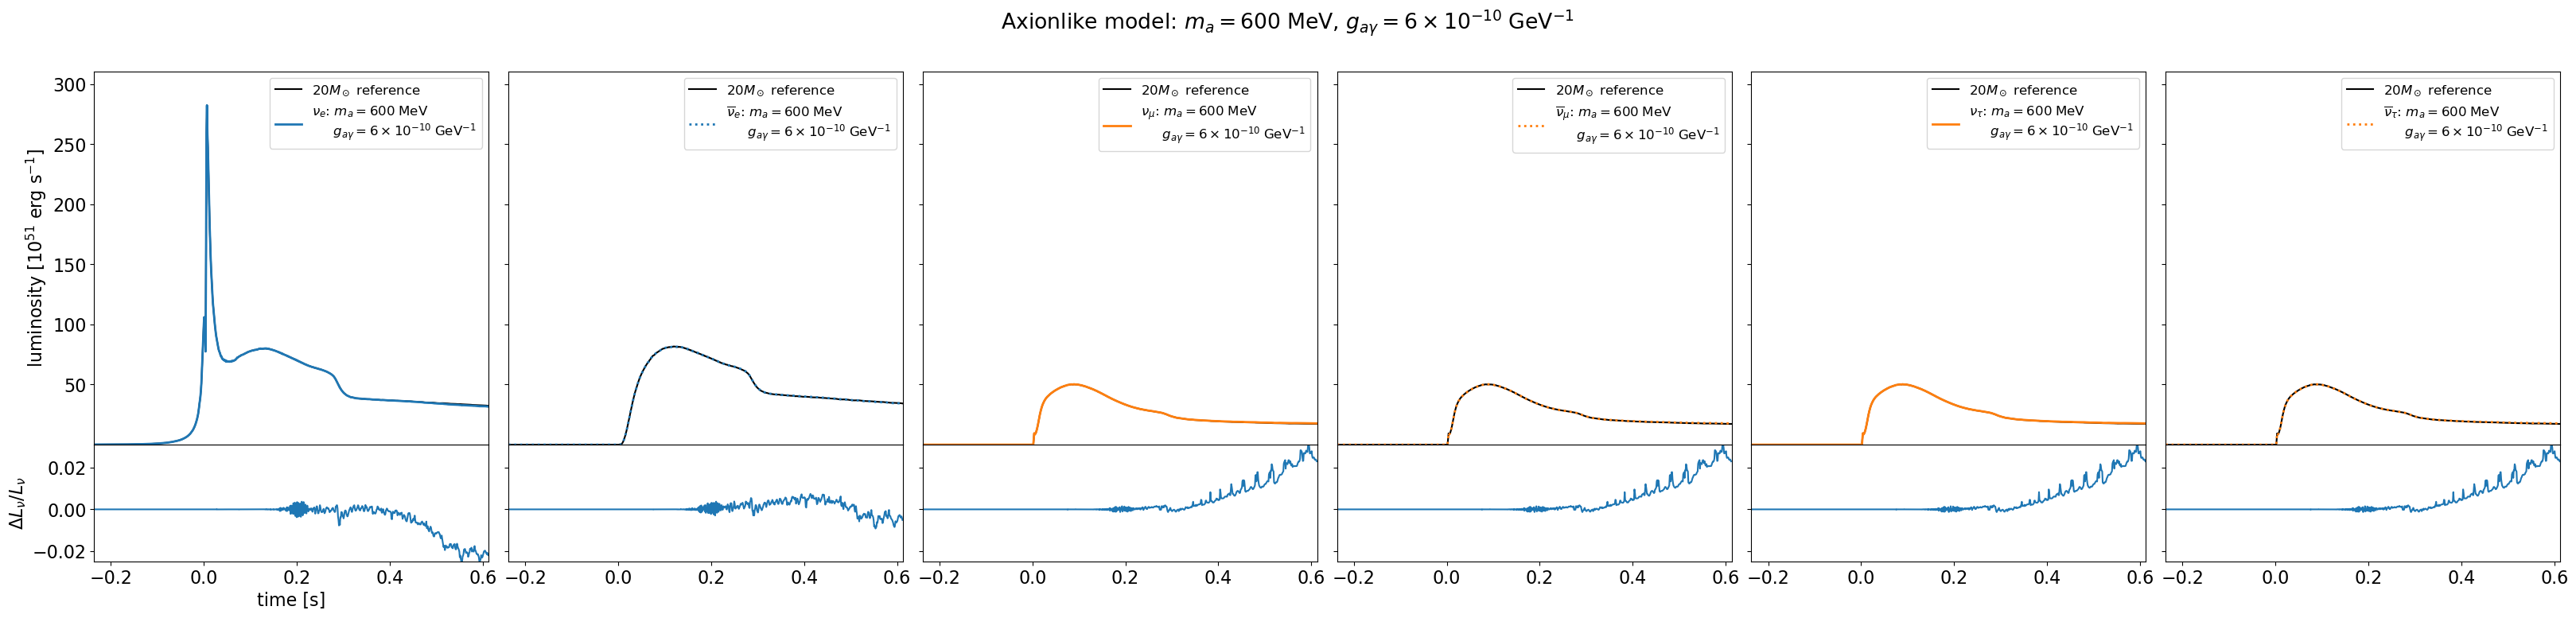

In [10]:
for (m,c), model in models.items():
    
    fig, axes = plt.subplots(2, 6, figsize=(40, 8), sharex=True,
                         gridspec_kw={'height_ratios':[3.2,1], 'hspace':0, 'wspace':0.05})
    
    Lmin,  Lmax  = 1e99, -1e99
    dLmin, dLmax = 1e99, -1e99
    
    for j, (flavor) in enumerate(Flavor):
        ax = axes[0][j]
        
        ax.plot(model_std.time, model_std.luminosity[flavor]/1e51, 'k', label=rf'${{{model_std.metadata["Progenitor mass"].to_value("Msun"):g}}}M_\odot$ reference')  # Report luminosity in [foe/s]
        Lmin = np.minimum(Lmin, np.min(model_std.luminosity[flavor].to_value('1e51 erg/s')))
        Lmax = np.maximum(Lmax, np.max(model_std.luminosity[flavor].to_value('1e51 erg/s')))
        
        modlabel = rf"{flavor.to_tex()}: $m_a=${m.to_string(format='latex_inline')}" + "\n" + rf"     $g_{{a\gamma}}=${c.to_string(format='latex_inline')}"
        ax.plot(model.time, model.luminosity[flavor]/1e51,  # Report luminosity in units foe/s
                label=modlabel,
                color='C0' if flavor.is_electron else 'C1',
                ls='-' if flavor.is_neutrino else ':',
                lw=2)
        if j==0:
            ax.set(ylabel=r'luminosity [$10^{51}$ erg s$^{-1}$]')
        
        ax.legend(fontsize=12)
        ax.set(xlim=(model_std.time[0].to_value('s'), model_std.time[-1].to_value('s')))
        
        ax = axes[1][j]
        tmin = np.maximum(model.time[0], model_std.time[0]).to_value('s')
        tmax = np.minimum(model.time[-1], model_std.time[-1]).to_value('s')
        times = np.arange(tmin, tmax, 0.001)*u.s

        Lstd = PchipInterpolator(model_std.time, model_std.luminosity[flavor].to_value('1e51 erg/s'))
        Lstd_t = Lstd(times)
        select = Lstd_t != 0
        
        Lmod = PchipInterpolator(model.time, model.luminosity[flavor].to_value('1e51 erg/s'))
        Lmod_t = Lmod(times)
        dL = (Lmod_t[select] - Lstd_t[select]) / Lstd_t[select]
        
        dLmin = np.minimum(dLmin, np.min(dL))
        dLmax = np.maximum(dLmax, np.max(dL))

        ax.plot(times[select], dL)
        if j==0:
            ax.set(xlabel='time [s]',
                   ylabel=r'$\Delta L_\nu/L_\nu$')
            
    for j in range(6):
        axes[0][j].set(ylim=(Lmin, 1.1*Lmax))
        axes[1][j].set(ylim=(dLmin, dLmax))
        if j > 0:
            axes[0][j].set_yticklabels([])
            axes[1][j].set_yticklabels([])
        
    fig.suptitle(rf"Axionlike model: $m_a=${m.to_string(format='latex_inline')}, $g_{{a\gamma}}=${c.to_string(format='latex_inline')}")

## Plot Model Spectra

Plot model spectra for the baseline model and a few of the alternative models for several times. Assume the progenitor is at a distance of 1 kpc.

In [11]:
t = np.arange(0.05, 0.35, 0.05) * u.s
E = np.arange(0, 50.1, 0.1) * u.MeV
d = 1*u.kpc

### Compare Baseline Model to 100 MeV ALP

Show the spectra from the ALP model at several times. The baseline model (no ALP) spectra are drawn as dashed lines.

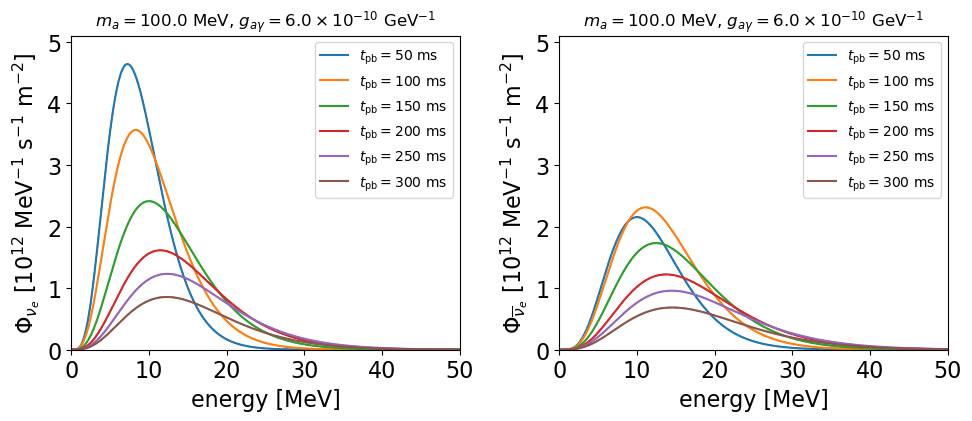

In [12]:
nt = t.shape[0]

fig, axes = plt.subplots(1,2, figsize=(10,4.5), sharex=True, tight_layout=True)

fmin, fmax = 0, -1e99

for fl in (Flavor.NU_E, Flavor.NU_E_BAR):
    ax = axes[fl]

    for j in np.arange(nt):
        color = None
        for i, model in enumerate([model_std, models[(100*u.MeV, 6e-10/u.GeV)]]):
            d2fdEdt = model.get_flux(t, E, d)
            dfdE = d2fdEdt.array[fl, j, :].to_value('1e12/(MeV s cm2)')
            fmax = np.maximum(fmax, np.max(dfdE))
            ls = '--' if i == 0 else '-'
            label = None if i == 0 else rf'$t_\text{{pb}}={t[j].to_value("ms"):g}$ ms'
            width = 1 if i==0 else 1.5
            line, = ax.plot(E, dfdE, label=label, ls=ls, lw=width, color=color)
            color = line.get_color()

    ax.set(xlim=E[[0,-1]].to_value(),
           xlabel='energy [MeV]',
           ylim=(fmin, 1.1*fmax),
           ylabel=rf'$\Phi_{{{fl.to_tex()[1:-1]}}}$ [$10^{{12}}$ MeV$^{{-1}}$ s$^{{-1}}$ m$^{{-2}}$]',
          )
    ax.set_title(rf'$m_a=\text{{{model.metadata["Axion mass"]}}}$, $g_{{a\gamma}}={model.metadata["Axion coupling"].to_value("1e-10/GeV")}\times10^{{-10}}$ GeV$^{{-1}}$', fontsize=12)
    
    ax.legend(loc='upper right', fontsize=10)

### Compare Baseline Model to 400 MeV ALP

Show the spectra from the ALP model at several times. The baseline model (no ALP) spectra are drawn as dashed lines.

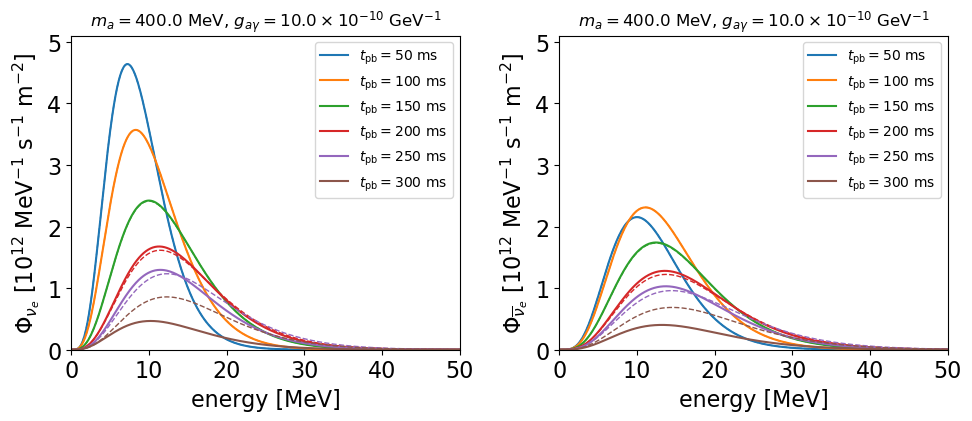

In [13]:
nt = t.shape[0]

fig, axes = plt.subplots(1,2, figsize=(10,4.5), sharex=True, tight_layout=True)

fmin, fmax = 0, -1e99

for fl in (Flavor.NU_E, Flavor.NU_E_BAR):
    ax = axes[fl]

    for j in np.arange(nt):
        color = None
        for i, model in enumerate([model_std, models[(400*u.MeV, 10e-10/u.GeV)]]):
            d2fdEdt = model.get_flux(t, E, d)
            dfdE = d2fdEdt.array[fl, j, :].to_value('1e12/(MeV s cm2)')
            fmax = np.maximum(fmax, np.max(dfdE))
            ls = '--' if i == 0 else '-'
            label = None if i == 0 else rf'$t_\text{{pb}}={t[j].to_value("ms"):g}$ ms'
            width = 1 if i==0 else 1.5
            line, = ax.plot(E, dfdE, label=label, ls=ls, lw=width, color=color)
            color = line.get_color()

    ax.set(xlim=E[[0,-1]].to_value(),
           xlabel='energy [MeV]',
           ylim=(fmin, 1.1*fmax),
           ylabel=rf'$\Phi_{{{fl.to_tex()[1:-1]}}}$ [$10^{{12}}$ MeV$^{{-1}}$ s$^{{-1}}$ m$^{{-2}}$]',
          )
    ax.set_title(rf'$m_a=\text{{{model.metadata["Axion mass"]}}}$, $g_{{a\gamma}}={model.metadata["Axion coupling"].to_value("1e-10/GeV")}\times10^{{-10}}$ GeV$^{{-1}}$', fontsize=12)
    
    ax.legend(loc='upper right', fontsize=10)